1. Import library dan pemanggilan file

In [1]:
import ast
import re
from collections import Counter
from functools import lru_cache
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from rank_bm25 import BM25Okapi
from Sastrawi.Stemmer.StemmerFactory import StemmerFactory
from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

pd.set_option("display.max_colwidth", 130)

# Mendukung kernel dijalankan dari ARTIKEL (1) maupun ARTIKEL (1)/Eksperiment3.
CWD = Path.cwd().resolve()
ROOT = next((p for p in (CWD, *CWD.parents)
             if all((p / f).is_file() for f in [
                 "corpus_faq.csv", "kamus_normalisasi.csv",
                 "queries_dev.csv", "queries_test.csv"])), None)
if ROOT is None:
    raise FileNotFoundError(
        f"Data CSV tidak ditemukan mulai dari working directory: {CWD}. "
        "Buka folder proyek ARTIKEL (1) atau folder Eksperiment3."
    )

OUTPUT_DIR = ROOT / "Eksperiment3" / "hasil_exp3"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

corpus = pd.read_csv(ROOT / "corpus_faq.csv", dtype={"doc_id": str})
kamus = pd.read_csv(ROOT / "kamus_normalisasi.csv")
dev_df = pd.read_csv(ROOT / "queries_dev.csv", dtype={"relevant_doc_id": str})
test_df = pd.read_csv(ROOT / "queries_test.csv", dtype={"relevant_doc_id": str})

for nama, df, kolom_wajib in [
    ("Corpus", corpus, ["doc_id", "pertanyaan_baku", "jawaban"]),
    ("Kamus", kamus, ["tidak_baku", "baku"]),
    ("Dev", dev_df, ["query_id", "query_text", "gaya_kueri", "relevant_doc_id"]),
    ("Test", test_df, ["query_id", "query_text", "gaya_kueri", "relevant_doc_id"]),
]:
    kurang = set(kolom_wajib) - set(df.columns)
    if kurang:
        raise KeyError(f"Kolom {nama} tidak ditemukan: {sorted(kurang)}")

if not set(dev_df["query_id"]).isdisjoint(set(test_df["query_id"])):
    raise ValueError("query_id dev dan test tumpang tindih. Gunakan split asli.")
if corpus["doc_id"].duplicated().any():
    raise ValueError("doc_id korpus tidak unik")
if dev_df["query_id"].duplicated().any() or test_df["query_id"].duplicated().any():
    raise ValueError("query_id dalam dev/test tidak unik")

print(f"ROOT   : {ROOT}")
print(f"Output : {OUTPUT_DIR}")
print(f"Corpus : {len(corpus)} dokumen")
print(f"Kamus  : {len(kamus)} baris")
print(f"Dev    : {len(dev_df)} kueri")
print(f"Test   : {len(test_df)} kueri")
display(dev_df.head(3))


ROOT   : D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)
Output : D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3
Corpus : 40 dokumen
Kamus  : 73 baris
Dev    : 166 kueri
Test   : 499 kueri


,query_id,query_text,gaya_kueri,relevant_doc_id,panjang_kata,rasio_tdk_baku,tokens_baseline
0,Q0108,"jika mahasiswa menghasilkan karya atau produk selama PI yang berpotensi didaftarkan HKI, apa yang perlu dilakukan",formal,FAQ039,16,0.0625,"['mahasiswa', 'hasil', 'karya', 'produk', 'lama', 'pi', 'potensi', 'daftar', 'hki', 'apa', 'perlu', 'laku']"
1,Q0039,"harusnya saya 3 orang ibu, tapi baru 2 orang dan sudah disetujui admin, jadi tidak bisa menambahkan teman saya",formal,FAQ011,19,0.0000,"['harus', '3', 'orang', 'ibu', 'baru', '2', 'orang', 'tuju', 'admin', 'jadi', 'tambah', 'teman']"
2,Q0451,"Mohon info, dosen pembimbing tidak bisa hadir untuk penarikan, bagaimana solusinya apakah bisa diwakilkan dosen lain",parafrase,FAQ025,16,0.0000,"['mohon', 'info', 'dosen', 'bimbing', 'hadir', 'tari', 'bagaimana', 'solusi', 'wakil', 'dosen']"


2. Preprocessing standar, indeks BM25, dan kosakata acuan

In [2]:
# Ini konsisten dengan preprocessing dan indeks BM25 pada Eksperimen 1 dan 2.
stemmer = StemmerFactory().create_stemmer()
stopwords_id = set(StopWordRemoverFactory().get_stop_words())

@lru_cache(maxsize=None)
def stem_cached(token):
    return stemmer.stem(token)

def case_fold(text):
    return str(text).lower()

def clean_regex(text):
    text = re.sub(r"[^a-z0-9\s]", " ", text)
    return re.sub(r"\s+", " ", text).strip()

def tokenize(text):
    return text.split()

def remove_stopwords(tokens):
    return [t for t in tokens if t not in stopwords_id]

def preprocess_standard(text, do_stem=True, do_stopword=True):
    tokens = tokenize(clean_regex(case_fold(text)))
    if do_stopword:
        tokens = remove_stopwords(tokens)
    if do_stem:
        tokens = [stem_cached(t) for t in tokens]
    return tokens

corpus["teks_indeks"] = (
    corpus["pertanyaan_baku"].fillna("").astype(str) + " "
    + corpus["jawaban"].fillna("").astype(str)
)
corpus_tokens = corpus["teks_indeks"].apply(preprocess_standard).tolist()
doc_ids = corpus["doc_id"].astype(str).tolist()

for label, df in [("Dev", dev_df), ("Test", test_df)]:
    tidak_ada = set(df["relevant_doc_id"]) - set(doc_ids)
    if tidak_ada:
        raise ValueError(f"{label} memuat ID FAQ tidak dikenal: {sorted(tidak_ada)}")

# Default rank_bm25, seperti Eksperimen 1 dan Eksperimen 2.
bm25 = BM25Okapi(corpus_tokens, k1=1.5, b=0.75)

# Kosakata acuan mengikuti Eksperimen 2: permukaan + hasil stemming + stopwords.
corpus_surface_tokens = []
for teks in corpus["teks_indeks"]:
    corpus_surface_tokens.extend(
        remove_stopwords(tokenize(clean_regex(case_fold(teks))))
    )
corpus_stemmed_tokens = [token for doc in corpus_tokens for token in doc]
vocab_freq = Counter(corpus_surface_tokens + corpus_stemmed_tokens)
vocab_acuan = set(vocab_freq) | stopwords_id

# Validasi konsistensi preprocessing dengan kolom token hasil baseline.
if "tokens_baseline" in dev_df.columns:
    n_beda = sum(
        preprocess_standard(row.query_text) != ast.literal_eval(row.tokens_baseline)
        for row in dev_df.itertuples(index=False)
    )
    print(f"Perbedaan token preprocessing dengan baseline di dev: {n_beda}")
    if n_beda:
        raise ValueError("Preprocessing tidak sama dengan hasil baseline. Periksa versi Sastrawi.")

print("Dokumen BM25:", len(doc_ids))
print("Ukuran kosakata acuan:", len(vocab_acuan))
print("BM25 k1=1.5, b=0.75; avgdl=", round(bm25.avgdl, 2))


Perbedaan token preprocessing dengan baseline di dev: 0
Dokumen BM25: 40
Ukuran kosakata acuan: 564
BM25 k1=1.5, b=0.75; avgdl= 26.23


3. Normalisasi kamus + Damerau-Levenshtein Distance

In [3]:
# A. Kamus: sama dengan Eksperimen 1 (longest-match, padanan multikata).
pasangan_kamus, entri_dilewati, seen = [], [], {}
for nomor, row in kamus.iterrows():
    asal_raw, baku_raw = row["tidak_baku"], row["baku"]
    if pd.isna(asal_raw) or pd.isna(baku_raw) or "/" in str(baku_raw):
        entri_dilewati.append((nomor, asal_raw, baku_raw))
        continue
    asal = tuple(tokenize(clean_regex(case_fold(asal_raw))))
    tujuan = tuple(tokenize(clean_regex(case_fold(baku_raw))))
    if not asal or not tujuan:
        entri_dilewati.append((nomor, asal_raw, baku_raw))
        continue
    if asal in seen and seen[asal] != tujuan:
        raise ValueError(f"Padanan kamus ambigu untuk {asal}")
    if asal not in seen:
        pasangan_kamus.append((asal, tujuan))
        seen[asal] = tujuan
pasangan_kamus.sort(key=lambda p: (-len(p[0]), p[0]))

def ganti_kamus_dengan_proteksi(tokens):
    """Kembalikan (token sesudah kamus, proteksi, log perubahan).
    Token dari padanan kamus tidak dikoreksi lagi oleh Damerau.
    """
    hasil, protected, log = [], [], []
    i = 0
    while i < len(tokens):
        found = False
        for asal, tujuan in pasangan_kamus:
            n = len(asal)
            if tuple(tokens[i:i+n]) == asal:
                hasil.extend(tujuan)
                protected.extend([True] * len(tujuan))
                log.append({
                    "asal": " ".join(asal), "tujuan": " ".join(tujuan),
                    "n_token_asal": len(asal),
                    "n_token_terkoreksi": sum(t not in stopwords_id for t in asal)
                })
                i += n
                found = True
                break
        if not found:
            hasil.append(tokens[i])
            protected.append(False)
            i += 1
    return hasil, protected, log

# B. Damerau-Levenshtein (restricted / OSA), mengikuti persis jenis operasi Eksperimen 2.
@lru_cache(maxsize=None)
def damerau_levenshtein_distance(s1, s2):
    len1, len2 = len(s1), len(s2)
    d = [[0] * (len2 + 1) for _ in range(len1 + 1)]
    for i in range(len1+1):
        d[i][0] = i
    for j in range(len2+1):
        d[0][j] = j
    for i in range(1, len1+1):
        for j in range(1, len2+1):
            cost = (s1[i-1] != s2[j-1])
            d[i][j] = min(
                d[i-1][j] + 1,
                d[i][j-1] + 1,
                d[i-1][j-1] + cost
            )
            if (i > 1 and j > 1 and
                s1[i-1] == s2[j-2] and s1[i-2] == s2[j-1]):
                d[i][j] = min(d[i][j], d[i-2][j-2] + 1)
    return d[len1][len2]

# Pengurutan kandidat membuat tie-breaking stabil dan bisa direplikasi.
vocab_urut = sorted(vocab_acuan)

@lru_cache(maxsize=None)
def cari_kandidat_terdekat(token):
    terbaik, jarak_terbaik, frek_terbaik = token, float("inf"), -1
    for cand in vocab_urut:
        if abs(len(token)-len(cand)) > jarak_terbaik:
            continue
        jarak = damerau_levenshtein_distance(token, cand)
        frek = vocab_freq[cand]
        if jarak < jarak_terbaik or (jarak == jarak_terbaik and frek > frek_terbaik):
            terbaik, jarak_terbaik, frek_terbaik = cand, jarak, frek
    return terbaik, jarak_terbaik

def koreksi_token_damerau(token, threshold, min_word_len=3):
    if (threshold <= 0 or token.isdigit() or len(token) < min_word_len or
        token in vocab_acuan or stem_cached(token) in vocab_acuan):
        return token, 0, False
    kandidat, jarak = cari_kandidat_terdekat(token)
    batas = min(threshold, 1) if len(token) <= 4 else threshold
    if jarak <= batas:
        return kandidat, jarak, True
    return token, jarak, False

# C. Gabungan: kamus -> Damerau pada token non-kamus -> stopword -> stem.
def preprocess_gabungan(text, threshold):
    token_awal = tokenize(clean_regex(case_fold(text)))
    hasil_kamus, protected, log_kamus = ganti_kamus_dengan_proteksi(token_awal)
    hasil_koreksi, log_dl = [], []
    for token, dilindungi in zip(hasil_kamus, protected):
        if dilindungi:
            hasil_koreksi.append(token)
            continue
        baru, jarak, berubah = koreksi_token_damerau(token, threshold)
        hasil_koreksi.append(baru)
        if berubah:
            log_dl.append({"asal": token, "tujuan": baru, "jarak": jarak})
    tokens_bm25 = [stem_cached(t) for t in remove_stopwords(hasil_koreksi)]
    return tokens_bm25, log_kamus, log_dl

print(f"Entri kamus asli: {len(kamus)} | Valid: {len(pasangan_kamus)} | Dilewati: {len(entri_dilewati)}")
if entri_dilewati:
    display(pd.DataFrame(entri_dilewati, columns=["baris_csv", "tidak_baku", "baku"]))


Entri kamus asli: 73 | Valid: 68 | Dilewati: 5


,baris_csv,tidak_baku,baku
0,64,mi,NaN
1,65,ki,NaN
2,66,ji,NaN
3,67,ta,kita/anda
4,69,tabe,permisi/maaf


4. Contoh perubahan normalisasi pada development set

In [4]:
# Contoh di dev set supaya mekanisme bisa ditinjau tanpa mengecek test terlebih dahulu.
contoh = dev_df[dev_df["gaya_kueri"].isin(["singkatan", "informal", "typo"])].head(9)

for row in contoh.itertuples(index=False):
    token, kamus_log, dl_log = preprocess_gabungan(row.query_text, threshold=2)
    keterangan_kamus = [f"{x['asal']} -> {x['tujuan']}" for x in kamus_log]
    keterangan_dl = [f"{x['asal']} -> {x['tujuan']} (d={x['jarak']})" for x in dl_log]
    print(f"[{row.query_id}] Gaya      : {row.gaya_kueri}")
    print(f"        Asli      : {row.query_text}")
    print(f"        Kamus     : {', '.join(keterangan_kamus) or '(tidak ada)'}")
    print(f"        Damerau   : {', '.join(keterangan_dl) or '(tidak ada)'}")
    print(f"        Token BM25: {token}\n")


[Q0038] Gaya      : informal
        Asli      : teman kelompok ku masih belum join dipengelompokan tapi sudah disetujui oleh admin
        Kamus     : (tidak ada)
        Damerau   : (tidak ada)
        Token BM25: ['teman', 'kelompok', 'ku', 'join', 'kelompok', 'tuju', 'admin']

[Q0182] Gaya      : informal
        Asli      : mau tanya, apa untuk mahasiswa Prodi Teknik Komputer yang sedang melaksanakan PI, mata kuliah PI wajib diprogramkan semester depan atau semester 7
        Kamus     : pi -> praktik industri, pi -> praktik industri
        Damerau   : tanya -> tanda (d=1), sedang -> bidang (d=2), depan -> kapan (d=2)
        Token BM25: ['mau', 'tanda', 'apa', 'mahasiswa', 'prodi', 'teknik', 'komputer', 'bidang', 'laksana', 'praktik', 'industri', 'mata', 'kuliah', 'praktik', 'industri', 'wajib', 'program', 'semester', 'kapan', 'semester', '7']

[Q0380] Gaya      : typo
        Asli      : nama aKprodi di dokumen IA masih menggunaakn nama lama padahal sudah ada pergantina, apakah

5. Tuning threshold Damerau 0–3 pada development set

In [5]:
def evaluate_gabungan(df, threshold, return_detail=False):
    """Metrik sesuai tabel Eksperimen 1/2; threshold=0 adalah Kamus saja."""
    if df.empty:
        raise ValueError("Subset evaluasi kosong.")

    hits1 = hits3 = hits5 = token_terkoreksi = token_kamus = token_damerau = 0
    total_token_sumber = 0
    reciprocal = []
    records = []

    for row in df.itertuples(index=False):
        raw_toks = tokenize(clean_regex(case_fold(row.query_text)))
        total_token_sumber += len(remove_stopwords(raw_toks))
        tokens, log_kamus, log_dl = preprocess_gabungan(row.query_text, threshold)

        n_kamus = sum(x["n_token_terkoreksi"] for x in log_kamus)
        n_dl = len(log_dl)
        token_kamus += n_kamus
        token_damerau += n_dl
        token_terkoreksi += n_kamus + n_dl

        scores = bm25.get_scores(tokens)
        idx = np.argsort(scores)[::-1]
        ranking = [doc_ids[i] for i in idx]
        true_doc = str(row.relevant_doc_id)
        rank = ranking.index(true_doc)+1
        hits1 += rank == 1
        hits3 += rank <= 3
        hits5 += rank <= 5
        reciprocal.append(1.0/rank)

        records.append({
            "query_id": row.query_id, "gaya_kueri": row.gaya_kueri,
            "query_text": row.query_text, "relevant_doc_id": true_doc,
            "prediksi_top1": ranking[0], "peringkat_benar": rank,
            "skor_top1": float(scores[idx[0]]), "hit1": int(rank == 1),
            "rr": 1.0/rank, "tokens_bm25": " ".join(tokens),
            "normalisasi_kamus": " | ".join(f"{x['asal']} -> {x['tujuan']}" for x in log_kamus),
            "koreksi_damerau": " | ".join(f"{x['asal']} -> {x['tujuan']} (d={x['jarak']})" for x in log_dl),
            "jumlah_padanan_kamus": len(log_kamus),
            "token_kamus": n_kamus, "token_damerau": n_dl,
            "token_terkoreksi": n_kamus+n_dl
        })
    n = len(df)
    hasil = {
        "Threshold": threshold,
        "Hit@1": hits1/n,
        "Hit@3": hits3/n,
        "Hit@5": hits5/n,
        "MRR": float(np.mean(reciprocal)),
        "Token_Terkoreksi": token_terkoreksi,
        "Rasio_Koreksi": token_terkoreksi/max(total_token_sumber, 1),
        "n": n,
        "Token_Kamus": token_kamus,
        "Token_Damerau": token_damerau
    }
    if return_detail:
        return hasil, pd.DataFrame(records)
    return hasil

thresholds = [0, 1, 2, 3]
tuning_rows = []
for d in thresholds:
    hasil = evaluate_gabungan(dev_df, d)
    khusus_typo = dev_df[dev_df["gaya_kueri"] == "typo"]
    if len(khusus_typo):
        sub = evaluate_gabungan(khusus_typo, d)
        hasil["Hit@1_Typo"] = sub["Hit@1"]
        hasil["MRR_Typo"] = sub["MRR"]
    else:
        hasil["Hit@1_Typo"] = np.nan
        hasil["MRR_Typo"] = np.nan
    tuning_rows.append(hasil)

tuning_df = pd.DataFrame(tuning_rows)
print("=== Tuning Damerau-Levenshtein + Kamus pada Development Set ===")
display(tuning_df.round(4))

# Agar sejalan dengan Eksperimen 2, threshold yang dipilih berasal dari d>0,
# diurutkan berdasarkan MRR dan Hit@1. d=0 = kontrol kamus saja.
kandidat = tuning_df[tuning_df["Threshold"] > 0].sort_values(
    ["MRR", "Hit@1", "Threshold"], ascending=[False, False, True]
)
best_threshold = int(kandidat.iloc[0]["Threshold"])
print(f"Threshold gabungan terpilih dari dev set: d <= {best_threshold}")

if tuning_df.loc[tuning_df["Threshold"] == 0, "MRR"].iloc[0] >= kandidat.iloc[0]["MRR"]:
    print("Catatan: MRR kamus saja (d=0) >= konfigurasi gabungan terpilih.")

tuning_df.to_csv(OUTPUT_DIR / "hasil_tuning_damerau_kamus_dev.csv", index=False)


=== Tuning Damerau-Levenshtein + Kamus pada Development Set ===


,Threshold,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n,Token_Kamus,Token_Damerau,Hit@1_Typo,MRR_Typo
0,0,0.9096,0.9759,0.994,0.9443,273,0.1712,166,273,0,0.875,0.9140
1,1,0.9157,0.9940,1.000,0.9520,421,0.2639,166,273,148,0.900,0.9458
2,2,0.9157,0.9940,1.000,0.9520,449,0.2815,166,273,176,0.900,0.9458
3,3,0.9337,0.9940,1.000,0.9610,482,0.3022,166,273,209,0.925,0.9583


Threshold gabungan terpilih dari dev set: d <= 3


6. Visualisasi tuning pada development set

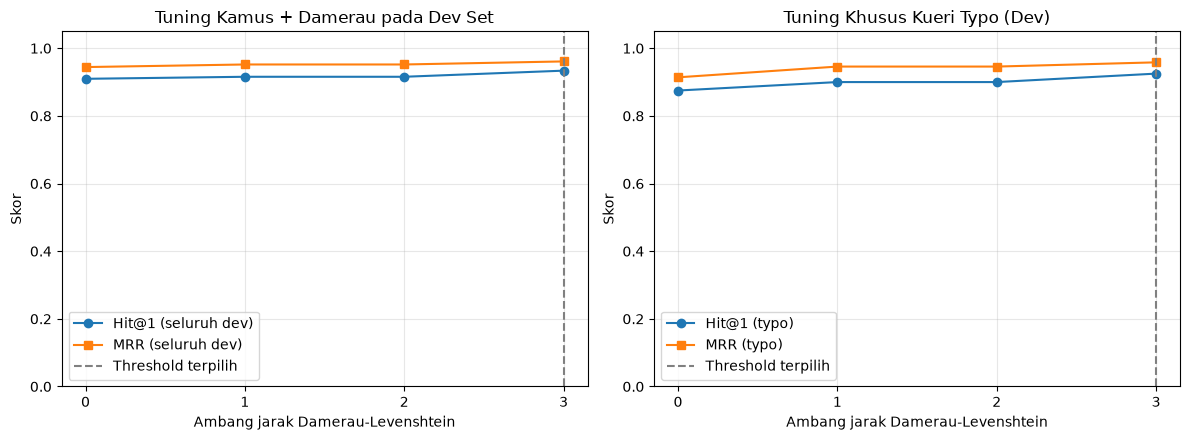

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
ax[0].plot(tuning_df["Threshold"], tuning_df["Hit@1"], marker="o", label="Hit@1 (seluruh dev)")
ax[0].plot(tuning_df["Threshold"], tuning_df["MRR"], marker="s", label="MRR (seluruh dev)")
ax[0].axvline(best_threshold, linestyle="--", color="gray", label="Threshold terpilih")
ax[0].set_title("Tuning Kamus + Damerau pada Dev Set")
ax[0].set_xlabel("Ambang jarak Damerau-Levenshtein")
ax[0].set_ylabel("Skor")
ax[0].set_xticks(thresholds)
ax[0].set_ylim(0, 1.05)
ax[0].grid(alpha=0.3)
ax[0].legend()

ax[1].plot(tuning_df["Threshold"], tuning_df["Hit@1_Typo"], marker="o", label="Hit@1 (typo)")
ax[1].plot(tuning_df["Threshold"], tuning_df["MRR_Typo"], marker="s", label="MRR (typo)")
ax[1].axvline(best_threshold, linestyle="--", color="gray", label="Threshold terpilih")
ax[1].set_title("Tuning Khusus Kueri Typo (Dev)")
ax[1].set_xlabel("Ambang jarak Damerau-Levenshtein")
ax[1].set_ylabel("Skor")
ax[1].set_xticks(thresholds)
ax[1].set_ylim(0, 1.05)
ax[1].grid(alpha=0.3)
ax[1].legend()

plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_tuning_damerau_kamus_dev.png", dpi=170)
plt.show()


7. Evaluasi test set: baseline, kamus, Damerau, dan kombinasi

In [7]:
# Parameter best_threshold sudah dibekukan berdasarkan dev set.
order = ["formal", "informal", "singkatan", "parafrase", "typo"]

# Baseline/Exp3 dihitung pada test set dengan indeks sama, untuk audit rank.
# Baseline = preprocess standar; Eksperimen 3 = kamus kemudian Damerau.
def evaluate_baseline(df, return_detail=False):
    if df.empty:
        raise ValueError("Subset kosong")
    records = []
    for row in df.itertuples(index=False):
        tokens = preprocess_standard(row.query_text)
        scores = bm25.get_scores(tokens)
        idx = np.argsort(scores)[::-1]
        ranking = [doc_ids[i] for i in idx]
        rank = ranking.index(str(row.relevant_doc_id)) + 1
        records.append({
            "query_id": row.query_id, "gaya_kueri": row.gaya_kueri,
            "query_text": row.query_text, "relevant_doc_id": str(row.relevant_doc_id),
            "peringkat_benar": rank, "prediksi_top1": ranking[0],
            "tokens_bm25": " ".join(tokens), "hit1": int(rank == 1),
            "rr": 1 / rank
        })
    detail = pd.DataFrame(records)
    n = len(detail)
    metrik = {
        "Hit@1": (detail["peringkat_benar"] == 1).mean(),
        "Hit@3": (detail["peringkat_benar"] <= 3).mean(),
        "Hit@5": (detail["peringkat_benar"] <= 5).mean(),
        "MRR": detail["rr"].mean(),
        "Token_Terkoreksi": 0, "Rasio_Koreksi": 0.0, "n": n
    }
    return (metrik, detail) if return_detail else metrik

baseline_test, detail_baseline = evaluate_baseline(test_df, return_detail=True)
gabungan_test, detail_gabungan = evaluate_gabungan(test_df, best_threshold, return_detail=True)

# Membaca hasil Eksp. 1/2 yang sebelumnya dibuat, agar angka pada grafik
# mencerminkan output notebook sebelumnya (tidak diisi angka manual).
file_exp1 = ROOT / "Eksperiment1" / "hasil_exp1" / "hasil_ringkasan_kamus_test.csv"
file_exp2 = ROOT / "Eksperiment2" / "hasil_ringkasan_levenshtein_test.csv"
file_gaya1 = ROOT / "Eksperiment1" / "hasil_exp1" / "hasil_per_gaya_kamus_test.csv"
file_gaya2 = ROOT / "Eksperiment2" / "hasil_per_gaya_levenshtein_test.csv"

for f in [file_exp1, file_exp2, file_gaya1, file_gaya2]:
    if not f.is_file():
        raise FileNotFoundError(
            f"File hasil eksperimen sebelumnya tidak ditemukan: {f}\n"
            "Jalankan dulu sel ekspor CSV pada Eksperimen 1/2, "
            "lalu jalankan ulang sel ini."
        )

hasil_exp1 = pd.read_csv(file_exp1)
hasil_exp2 = pd.read_csv(file_exp2)
gaya_exp1 = pd.read_csv(file_gaya1)
gaya_exp2 = pd.read_csv(file_gaya2)

wajib_ringkasan = ["Konfigurasi", "Hit@1", "Hit@3", "Hit@5", "MRR", "Token_Terkoreksi", "Rasio_Koreksi", "n"]
for label, df in [("Exp1", hasil_exp1), ("Exp2", hasil_exp2)]:
    kurang = set(wajib_ringkasan) - set(df.columns)
    if kurang:
        raise ValueError(f"Kolom ringkasan {label} hilang: {sorted(kurang)}")
    if len(df) < 2 or any(df["n"] != len(test_df)):
        raise ValueError(f"Ringkasan {label} tidak menggunakan test set yang sama ({len(test_df)}).")

# Periksa kesesuaian baseline dari dua CSV dengan baseline yang dihitung sekarang.
for label, df in [("Exp1", hasil_exp1), ("Exp2", hasil_exp2)]:
    for m in ["Hit@1", "Hit@3", "Hit@5", "MRR"]:
        beda = abs(float(df.iloc[0][m]) - float(baseline_test[m]))
        if beda > 1e-7:
            raise ValueError(
                f"Baseline {label} berbeda pada {m} (selisih {beda:.6g}). "
                "Periksa versi korpus, preprocessing, atau split."
            )

# Eksp. 2 memilih d secara terpisah dari dev set; baca nama konfigurasinya dari CSV.
# Keempat baris: baseline, kamus, Damerau, kombinasi.
baris_gabungan = {k: gabungan_test[k] for k in wajib_ringkasan if k != "Konfigurasi"}
baris_gabungan["Konfigurasi"] = f"BM25 + Kamus + Damerau-Levenshtein (d <= {best_threshold})"

summary_test = pd.DataFrame([
    {**hasil_exp2.iloc[0][wajib_ringkasan].to_dict(), "Konfigurasi": "Baseline (BM25 Tanpa Koreksi)"},
    hasil_exp1.iloc[1][wajib_ringkasan].to_dict(),
    {**hasil_exp2.iloc[1][wajib_ringkasan].to_dict(), "Konfigurasi": hasil_exp2.iloc[1]["Konfigurasi"].replace("Levenshtein", "Damerau-Levenshtein")},
    baris_gabungan
])[wajib_ringkasan].reset_index(drop=True)

print(f"=== Perbandingan Kinerja Keseluruhan Test Set (n = {len(test_df)}) ===")
display(summary_test.round(4))

# Per gaya: gunakan hasil asli Exp1/Exp2 untuk 3 metode pertama.
kolom_gaya1 = ["Gaya Kueri", "n", "Hit@1_Baseline", "Hit@1_Kamus", "MRR_Baseline", "MRR_Kamus"]
kolom_gaya2 = ["Gaya Kueri", "n", "Hit@1_Baseline", "Hit@1_Levenshtein", "MRR_Baseline", "MRR_Levenshtein"]
for label, df, kolom in [("Exp1", gaya_exp1, kolom_gaya1), ("Exp2", gaya_exp2, kolom_gaya2)]:
    if set(kolom) - set(df.columns):
        raise ValueError(f"Kolom per gaya {label} tidak sesuai dengan notebook sebelumnya")

per_gaya_rows = []
for gaya in order:
    sub = test_df[test_df["gaya_kueri"] == gaya]
    if sub.empty:
        continue
    x1 = gaya_exp1.loc[gaya_exp1["Gaya Kueri"] == gaya]
    x2 = gaya_exp2.loc[gaya_exp2["Gaya Kueri"] == gaya]
    if len(x1) != 1 or len(x2) != 1:
        raise ValueError(f"Gaya '{gaya}' tidak ditemukan tepat satu kali pada CSV Exp1/2")
    x1, x2 = x1.iloc[0], x2.iloc[0]
    if int(x1["n"]) != len(sub) or int(x2["n"]) != len(sub):
        raise ValueError(f"Jumlah data per gaya '{gaya}' tidak sama")
    res_gab = evaluate_gabungan(sub, best_threshold)
    res_base = evaluate_baseline(sub)
    if abs(x1["Hit@1_Baseline"] - res_base["Hit@1"]) > 1e-7 or abs(x2["MRR_Baseline"] - res_base["MRR"]) > 1e-7:
        raise ValueError(f"Baseline tidak konsisten pada gaya '{gaya}'")
    per_gaya_rows.append({
        "Gaya Kueri": gaya, "n": len(sub),
        "Hit@1_Baseline": res_base["Hit@1"], "Hit@1_Kamus": float(x1["Hit@1_Kamus"]),
        "Hit@1_Damerau": float(x2["Hit@1_Levenshtein"]), "Hit@1_Gabungan": res_gab["Hit@1"],
        "MRR_Baseline": res_base["MRR"], "MRR_Kamus": float(x1["MRR_Kamus"]),
        "MRR_Damerau": float(x2["MRR_Levenshtein"]), "MRR_Gabungan": res_gab["MRR"],
        "Delta_Hit@1_Gabungan_vs_Baseline": res_gab["Hit@1"] - res_base["Hit@1"],
        "Delta_MRR_Gabungan_vs_Baseline": res_gab["MRR"] - res_base["MRR"]
    })
per_gaya_df = pd.DataFrame(per_gaya_rows)
print("\n=== Perbandingan per Gaya Kueri pada Test Set ===")
display(per_gaya_df.round(4))

summary_test.to_csv(OUTPUT_DIR / "hasil_ringkasan_empat_konfigurasi_test.csv", index=False)
per_gaya_df.to_csv(OUTPUT_DIR / "hasil_per_gaya_empat_konfigurasi_test.csv", index=False)
detail_gabungan.to_csv(OUTPUT_DIR / "detail_gabungan_test.csv", index=False)
detail_baseline.to_csv(OUTPUT_DIR / "detail_baseline_test.csv", index=False)
print("Ringkasan empat konfigurasi dan per gaya tersimpan di:", OUTPUT_DIR)


=== Perbandingan Kinerja Keseluruhan Test Set (n = 499) ===


,Konfigurasi,Hit@1,Hit@3,Hit@5,MRR,Token_Terkoreksi,Rasio_Koreksi,n
0,Baseline (BM25 Tanpa Koreksi),0.9519,0.988,0.994,0.9698,0,0.0000,499
1,BM25 + Normalisasi Kamus,0.8397,0.976,0.986,0.9044,899,0.1786,499
2,BM25 + Damerau-Levenshtein (d <= 2),0.9699,0.988,0.996,0.9800,701,0.1393,499
3,BM25 + Kamus + Damerau-Levenshtein (d <= 3),0.8617,0.984,0.990,0.9186,1517,0.3014,499



=== Perbandingan per Gaya Kueri pada Test Set ===


,Gaya Kueri,n,Hit@1_Baseline,Hit@1_Kamus,Hit@1_Damerau,Hit@1_Gabungan,MRR_Baseline,MRR_Kamus,MRR_Damerau,MRR_Gabungan,Delta_Hit@1_Gabungan_vs_Baseline,Delta_MRR_Gabungan_vs_Baseline
0,formal,59,0.9661,0.8644,0.9661,0.8814,0.9753,0.9214,0.9752,0.9327,-0.0847,-0.0426
1,informal,109,1.0000,0.8532,1.0000,0.8624,1.0000,0.9148,1.0000,0.9216,-0.1376,-0.0784
2,singkatan,107,0.9720,0.8785,0.9907,0.8972,0.9825,0.9330,0.9930,0.9424,-0.0748,-0.0401
3,parafrase,104,0.8654,0.7981,0.9038,0.7885,0.9186,0.8720,0.9394,0.8696,-0.0769,-0.0490
4,typo,120,0.9583,0.8167,0.9833,0.8833,0.9727,0.8892,0.9879,0.9301,-0.0750,-0.0426


Ringkasan empat konfigurasi dan per gaya tersimpan di: D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3


8. Visualisasi perbandingan empat konfigurasi pada test set

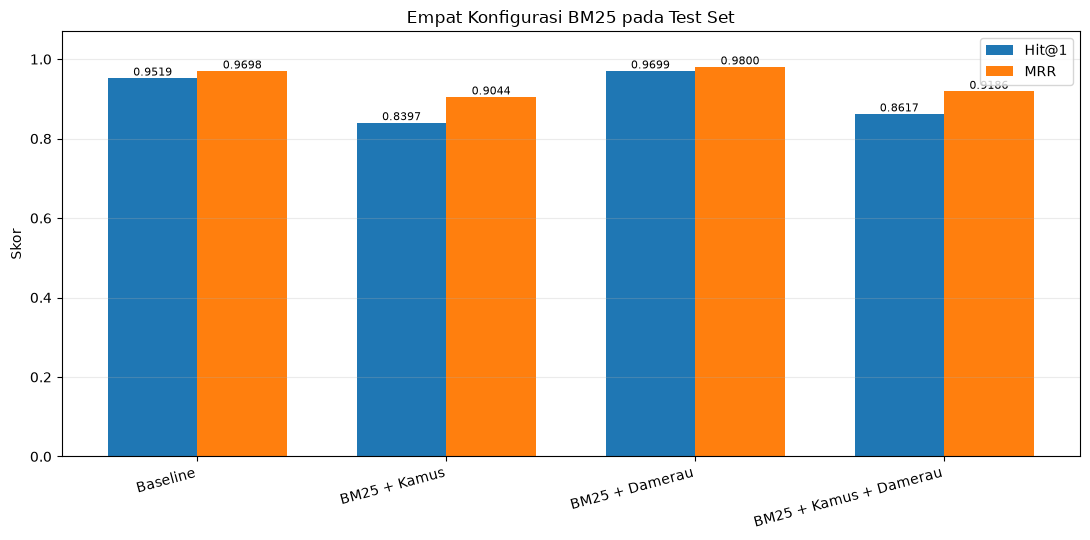

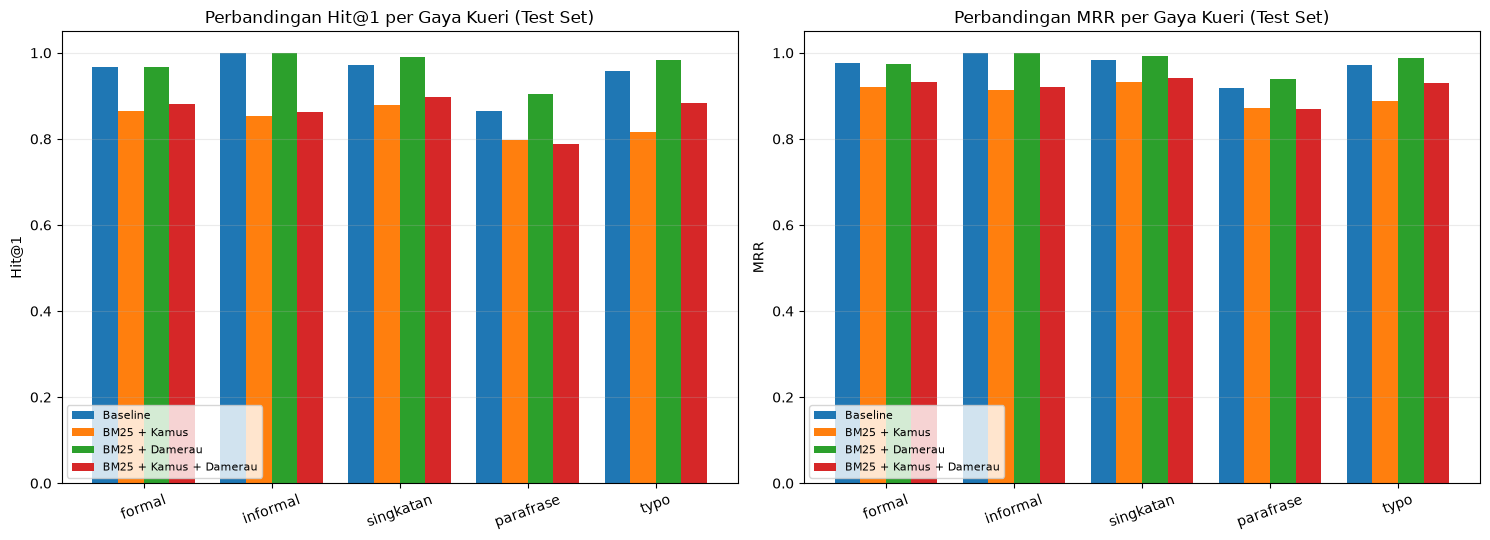

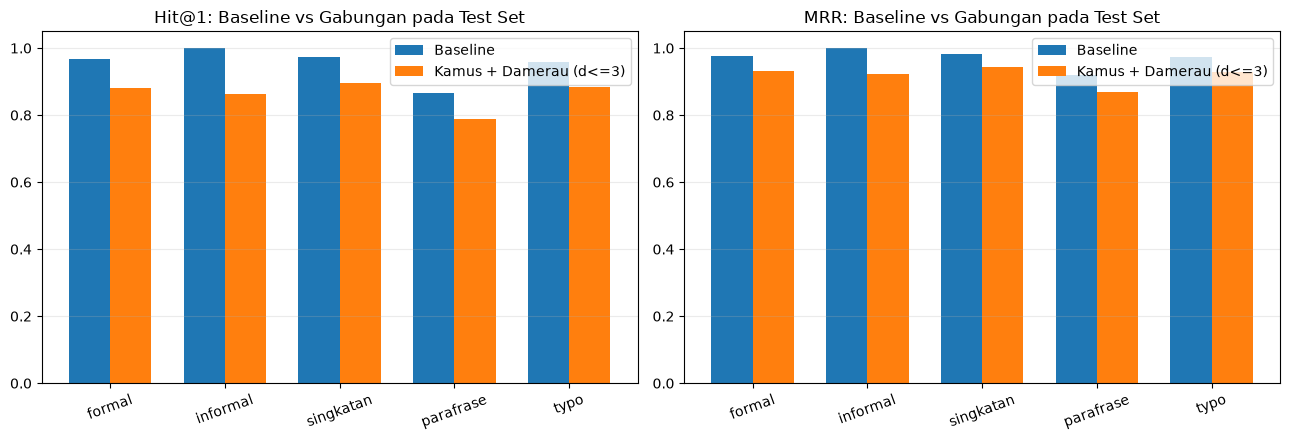

In [8]:
# Empat konfigurasi, satu kurva/batang untuk masing-masing hasil asli.
label_singkat = ["Baseline", "BM25 + Kamus", "BM25 + Damerau", "BM25 + Kamus + Damerau"]

# (A) Perbandingan keseluruhan: Hit@1 dan MRR berdampingan.
x = np.arange(4)
width = 0.36
fig, ax = plt.subplots(figsize=(11, 5.5))
a = ax.bar(x - width/2, summary_test["Hit@1"], width, label="Hit@1")
b = ax.bar(x + width/2, summary_test["MRR"], width, label="MRR")
ax.set_xticks(x, label_singkat, rotation=15, ha="right")
ax.set_ylabel("Skor")
ax.set_ylim(0, 1.07)
ax.set_title("Empat Konfigurasi BM25 pada Test Set")
ax.grid(axis="y", alpha=0.25)
ax.legend()
for kumpulan in (a, b):
    for batang in kumpulan:
        ax.annotate(f"{batang.get_height():.4f}",
                    (batang.get_x()+batang.get_width()/2, batang.get_height()),
                    ha="center", va="bottom", fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_empat_konfigurasi_keseluruhan_test.png", dpi=180)
plt.show()

# (B) Per gaya: empat konfigurasi dibandingkan pada kedua metrik.
x = np.arange(len(per_gaya_df))
w = 0.2
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
plot_specs = [
    ("Baseline", "Baseline"), ("Kamus", "BM25 + Kamus"),
    ("Damerau", "BM25 + Damerau"), ("Gabungan", "BM25 + Kamus + Damerau")
]
for panel, metrik in zip(ax, ["Hit@1", "MRR"]):
    for j, (kolom, label) in enumerate(plot_specs):
        panel.bar(x + (j-1.5)*w, per_gaya_df[f"{metrik}_{kolom}"], w, label=label)
    panel.set_xticks(x, per_gaya_df["Gaya Kueri"], rotation=20)
    panel.set_ylim(0, 1.05)
    panel.set_title(f"Perbandingan {metrik} per Gaya Kueri (Test Set)")
    panel.set_ylabel(metrik)
    panel.grid(axis="y", alpha=0.25)
    panel.legend(fontsize=8, loc="lower left")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_empat_konfigurasi_per_gaya_test.png", dpi=180)
plt.show()

# (C) Grafik selaras format Exp1/Exp2: baseline versus kombinasi.
x = np.arange(len(per_gaya_df))
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for panel, metrik in zip(ax, ["Hit@1", "MRR"]):
    panel.bar(x-0.18, per_gaya_df[f"{metrik}_Baseline"], 0.36, label="Baseline")
    panel.bar(x+0.18, per_gaya_df[f"{metrik}_Gabungan"], 0.36, label=f"Kamus + Damerau (d<={best_threshold})")
    panel.set_xticks(x, per_gaya_df["Gaya Kueri"], rotation=20)
    panel.set_ylim(0, 1.05)
    panel.set_title(f"{metrik}: Baseline vs Gabungan pada Test Set")
    panel.legend()
    panel.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "fig_gabungan_vs_baseline_test.png", dpi=180)
plt.show()


9. Audit perubahan peringkat dan koreksi berlebih (test set)

In [9]:
# Analisis perubahan peringkat dokumen relevan dari baseline menjadi gabungan.
kasus = detail_baseline[[
    "query_id", "gaya_kueri", "query_text", "relevant_doc_id",
    "tokens_bm25", "peringkat_benar", "prediksi_top1"
]].merge(
    detail_gabungan[[
        "query_id", "tokens_bm25", "peringkat_benar", "prediksi_top1",
        "normalisasi_kamus", "koreksi_damerau", "jumlah_padanan_kamus",
        "token_kamus", "token_damerau", "token_terkoreksi"
    ]], on="query_id", suffixes=("_base", "_gabungan"), validate="one_to_one"
)

kasus["status"] = np.select(
    [kasus["peringkat_benar_gabungan"] < kasus["peringkat_benar_base"],
     kasus["peringkat_benar_gabungan"] > kasus["peringkat_benar_base"]],
    ["Membaik", "Memburuk"], default="Tetap"
)
kasus_berubah = kasus[kasus["status"] != "Tetap"].copy()
audit_normalisasi = kasus[kasus["token_terkoreksi"] > 0].copy()

print(f"Total perubahan peringkat: {len(kasus_berubah)}")
print(kasus["status"].value_counts().to_string())
print(f"Kueri dengan kamus dan/atau Damerau: {len(audit_normalisasi)}")
if len(kasus_berubah):
    display(kasus_berubah.head(15))

kasus_berubah.to_csv(OUTPUT_DIR / "kasus_perubahan_peringkat_gabungan_test.csv", index=False)
audit_normalisasi.to_csv(OUTPUT_DIR / "audit_normalisasi_gabungan_test.csv", index=False)
kasus.to_csv(OUTPUT_DIR / "seluruh_peringkat_gabungan_vs_baseline_test.csv", index=False)
print("Audit hasil tersimpan di", OUTPUT_DIR)


Total perubahan peringkat: 66
status
Tetap       433
Memburuk     58
Membaik       8
Kueri dengan kamus dan/atau Damerau: 480


,query_id,gaya_kueri,query_text,relevant_doc_id,tokens_bm25_base,peringkat_benar_base,prediksi_top1_base,tokens_bm25_gabungan,peringkat_benar_gabungan,prediksi_top1_gabungan,normalisasi_kamus,koreksi_damerau,jumlah_padanan_kamus,token_kamus,token_damerau,token_terkoreksi,status
5,Q0040,parafrase,"akun tim saya belum di verifikasi, saya tidak bisa menambahkannya sebagai anggota tim",FAQ011,akun tim verifikasi tambah anggota tim,2,FAQ010,akun nim verifikasi tambah anggota nim,3,FAQ019,,tim -> nim (d=1) | tim -> nim (d=1),0,0,2,2,Memburuk
26,Q0121,parafrase,"Mohon info, seperti apa langkah registrasi akun mahasiswa di SiPi?",FAQ001,mohon info apa langkah registrasi akun mahasiswa sipi,3,FAQ015,mohon info apa lengkap registrasi akun mahasiswa sistem informasi praktik industri,2,FAQ015,sipi -> sistem informasi praktik industri,langkah -> lengkap (d=2),1,1,1,2,Membaik
46,Q0006,informal,akun sipi ku belum terverifikasi,FAQ002,akun sipi ku verifikasi,1,FAQ002,akun sistem informasi praktik industri ku verifikasi,3,FAQ012,sipi -> sistem informasi praktik industri,,1,1,0,1,Memburuk
50,Q0345,singkatan,"misi, apabila pihak perusahaan tdk bersedia menandatangani SPK dan IA, dokumen apa yg prlu diunggah sebagai gantinya",FAQ018,misi apabila pihak usaha tdk sedia menandatangani spk dokumen apa yg prlu unggah ganti,1,FAQ018,isi ambil pihak usaha sedia menandatangani surat nyata kerjasama implementation arrangement dokumen apa perlu unduh ganti,2,FAQ017,tdk -> tidak | spk -> surat pernyataan kerjasama | ia -> implementation arrangement | yg -> yang | prlu -> perlu,misi -> isi (d=1) | apabila -> ambil (d=3) | diunggah -> diunduh (d=3),5,4,3,7,Memburuk
56,Q0256,parafrase,"Izin bertanya, harusnya saya 3 orang ibu, tapi baru 2 orang dan sudah disetujui admin, jadi tidak bisa menambahkan teman saya",FAQ011,izin tanya harus 3 orang ibu baru 2 orang tuju admin jadi tambah teman,1,FAQ011,izin berapa harus 3 ulang baru 2 ulang tuju admin jadi tambah teman,2,FAQ028,,bertanya -> berapa (d=3) | orang -> ulang (d=2) | ibu -> itu (d=1) | orang -> ulang (d=2),0,0,4,4,Memburuk
57,Q0082,informal,cara pengajuan selesai pi gimana di sipi,FAQ027,cara aju selesai pi gimana sipi,1,FAQ027,cara aju selesai praktik industri bagaimana sistem informasi praktik industri,2,FAQ012,pi -> praktik industri | gimana -> bagaimana | sipi -> sistem informasi praktik industri,,3,3,0,3,Memburuk
61,Q0060,informal,"klo perusahaan gamau ttd spk ia, upload apa gantinya",FAQ018,klo usaha gamau ttd spk upload apa ganti,1,FAQ018,kalau usaha nama tanda tangan surat nyata kerjasama implementation arrangement upload apa ganti,2,FAQ017,klo -> kalau | ttd -> tanda tangan | spk -> surat pernyataan kerjasama | ia -> implementation arrangement,gamau -> nama (d=2),4,3,1,4,Memburuk
64,Q0052,singkatan,sblm pi dokumen apa aja yg hrs didownload,FAQ015,sblm pi dokumen apa aja yg hrs didownload,2,FAQ029,praktik industri dokumen apa apa didownload,1,FAQ015,sblm -> sebelum | pi -> praktik industri | yg -> yang | hrs -> harus,aja -> apa (d=1),4,4,1,5,Membaik
65,Q0061,parafrase,dibagian SPK dan IA bertanda wajib apakah yang diupload adalah file laporan PI juga jadi file yang diupload double,FAQ018,bagi spk tanda wajib diupload file lapor pi jadi file diupload double,1,FAQ018,bagi surat nyata kerjasama implementation arrangement tanda wajib diupload file lapor praktik industri jadi file diupload google,3,FAQ017,spk -> surat pernyataan kerjasama | ia -> implementation arrangement | pi -> praktik industri,double -> google (d=3),3,2,1,3,Memburuk
78,Q0476,typo,bagaimana cara melakkuan pengajuan Selesai PI di SiPi,FAQ027,bagaimana cara melakkuan aju selesai pi sipi,1,FAQ027,bagaimana cara laku aju selesai praktik industri sistem informasi praktik industri,3,FAQ012,pi -> praktik industri | sipi -> sistem informasi praktik industri,melakkuan -> melakukan (d=1),2,2,1,3,Memburuk


Audit hasil tersimpan di D:\Folder KULIAH\Sistem Temu Kembali\Artikel (1)\Eksperiment3\hasil_exp3
